# Lesson 5 — Calibration: choosing the partial factors

Lesson 4 showed the reliability the present code delivers: 3.74 on
average, between 2.5 and 4.5 across the design situations. Calibration
asks which partial factors bring all situations *as close as possible* to
the target $\beta_t = 3.8$:

$$ \min_{\gamma}\; M(\gamma) = \sum_k w_k \big(\beta_k(\gamma) - \beta_t\big)^2 . $$

A single pair $(\gamma_G, \gamma_Q)$ cannot hit 3.8 everywhere — β falls
with $a_Q$ for any fixed pair — so the optimum is a compromise weighted
by how common each situation is. More free parameters (separate factors
per load, a ξ for the two-combination equations) buy a smaller residual
scatter at the price of a more complicated code.

Each evaluation of $M$ runs FORM for 810 situations (about a second);
a calibration needs 20–60 of them.

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd

try:
    import codecal as cc
except ImportError:
    sys.path.insert(0, os.path.abspath('..'))
    import codecal as cc
from codecal import plots
from codecal.plots import Figure

FIG = 'figures'
os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 120)


def save(fig, name):
    """Save a figure next to the lesson and show it (inline in Jupyter/Spyder)."""
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')
    try:
        from IPython.display import display
        display(fig)
    except ImportError:            # plain python: the PNG in figures/ is the output
        pass


model = cc.ahg_model()

## 1. The objective function as a landscape

Before optimising, look at $M(\gamma_G, \gamma_Q)$ on a grid (with a
coarser sweep of 108 situations so that it takes seconds). The valley
is long and shallow along one direction: raising $\gamma_G$ and lowering
$\gamma_Q$ (or vice versa) changes the objective little — the two factors
can partly substitute each other, which is why calibrated values should
always be reported together with the equation and weights they belong to.
(The coarse sweep shifts the minimum a little compared with the full
model used below.)

grid of 121 objective evaluations in 12 s


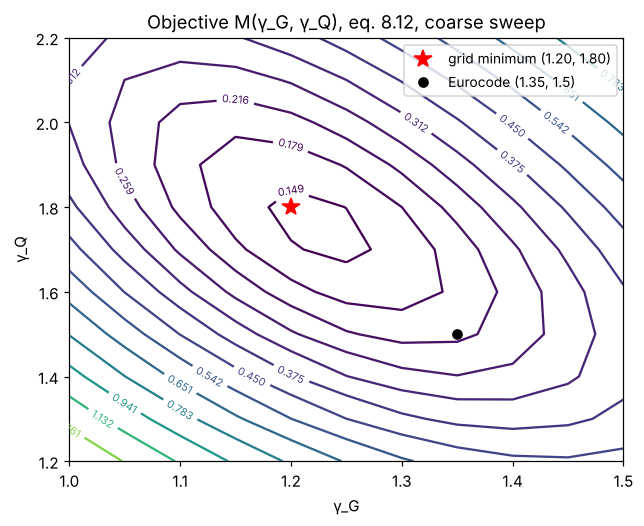

In [2]:
coarse = cc.ahg_model(n_mcs=1_000_000, n_aQ=4, n_aG=1)
gG = np.linspace(1.0, 1.5, 11)
gQ = np.linspace(1.2, 2.2, 11)
M = np.zeros((len(gQ), len(gG)))
t0 = time.time()
for i, q in enumerate(gQ):
    for j, g in enumerate(gG):
        df = cc.evaluate(coarse, cc.START_VALUES.with_values(['gamma_G', 'gamma_Q'], [g, q]))
        M[i, j] = cc.objective(df, 3.8)
print(f"grid of {M.size} objective evaluations in {time.time() - t0:.0f} s")

fig = Figure(figsize=(6.5, 5))
ax = fig.subplots()
cs = ax.contour(gG, gQ, M, levels=np.geomspace(M.min() * 1.05, M.max(), 14), cmap='viridis')
ax.clabel(cs, fontsize=7, fmt='%.3f')
i, j = np.unravel_index(M.argmin(), M.shape)
ax.plot(gG[j], gQ[i], 'r*', ms=12, label=f'grid minimum ({gG[j]:.2f}, {gQ[i]:.2f})')
ax.plot(1.35, 1.5, 'ko', label='Eurocode (1.35, 1.5)')
ax.set_xlabel('γ_G')
ax.set_ylabel('γ_Q')
ax.set_title('Objective M(γ_G, γ_Q), eq. 8.12, coarse sweep')
ax.legend(loc='upper right', fontsize=9)
save(fig, 'lesson05_objective_landscape.png')

## 2. Calibrating γ_G and γ_Q for eq. 8.12

`calibrate` minimises $M$ with SLSQP. `free` names the parameters the
optimiser may change; the others keep their start values. The printout
shows every objective evaluation.

In [3]:
t0 = time.time()
cal_12 = cc.calibrate(model, free=('gamma_G', 'gamma_Q'), equation='8.12', start=cc.START_VALUES)
print(f"\n{cal_12}\n({time.time() - t0:.0f} s)")

  eval   1: gamma_G=1.3500, gamma_Q=1.5000  M = 1.889e-01


  eval   2: gamma_G=1.3501, gamma_Q=1.5000  M = 1.889e-01


  eval   3: gamma_G=1.3500, gamma_Q=1.5001  M = 1.889e-01


  eval   4: gamma_G=1.1493, gamma_Q=1.8187  M = 1.464e-01


  eval   5: gamma_G=1.1494, gamma_Q=1.8187  M = 1.464e-01


...

  eval  13: gamma_G=1.2234, gamma_Q=1.7316  M = 1.369e-01


  eval  14: gamma_G=1.2154, gamma_Q=1.7505  M = 1.366e-01


  eval  15: gamma_G=1.2155, gamma_Q=1.7505  M = 1.366e-01


  eval  16: gamma_G=1.2154, gamma_Q=1.7506  M = 1.366e-01



calibrated gamma_G, gamma_Q  (β_t = 3.8)
  gamma_G            1.215
  gamma_Q            1.750
  weighted-mean β  3.741 → 3.809
  objective        1.366e-01   (16 evaluations)
(16 s)


The optimiser lowers $\gamma_G$ and raises $\gamma_Q$: the status quo was
too conservative for permanent-load-dominated structures and not
conservative enough for variable-load-dominated ones, exactly what the
falling β–$a_Q$ curves of lesson 4 said. The weighted mean lands close
to 3.8 by construction; what matters is the *scatter* around it:

spread of β (weighted std):  before 0.441   after 0.383


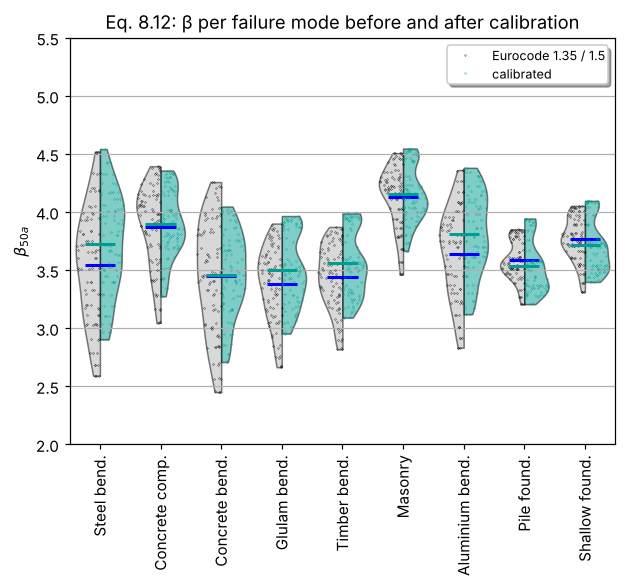

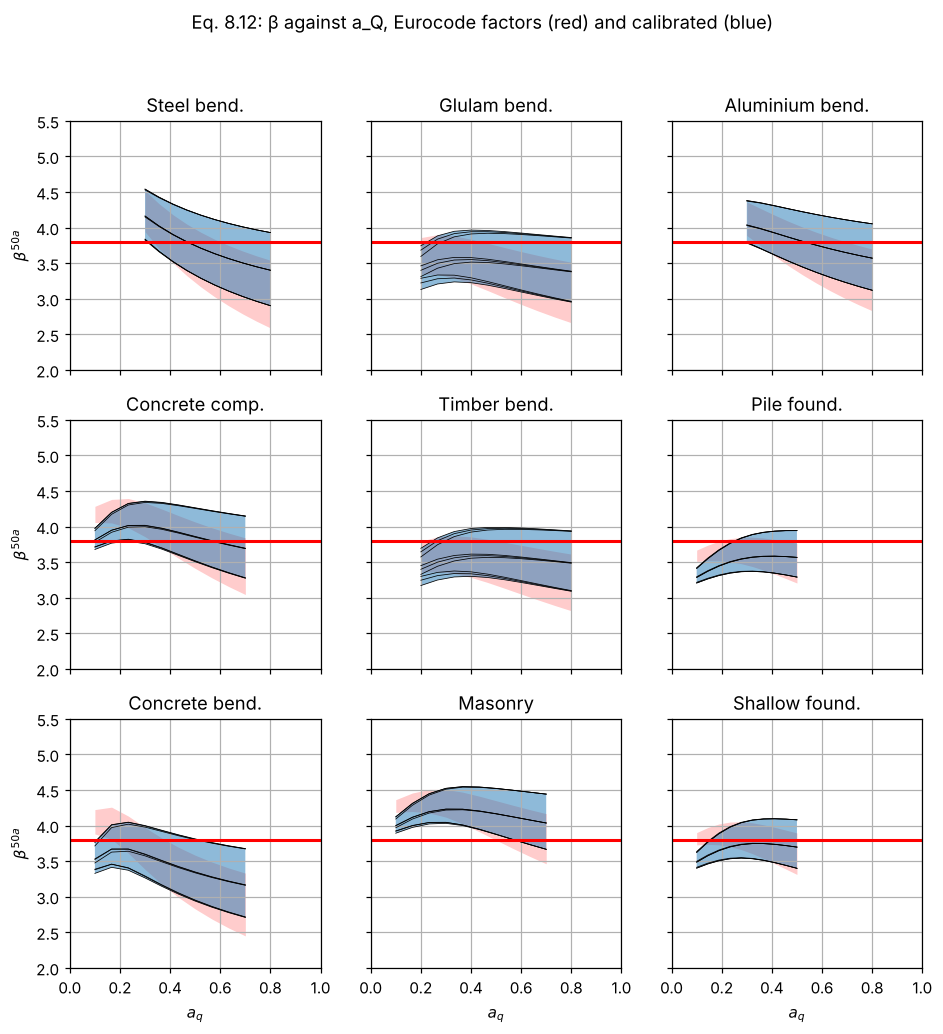

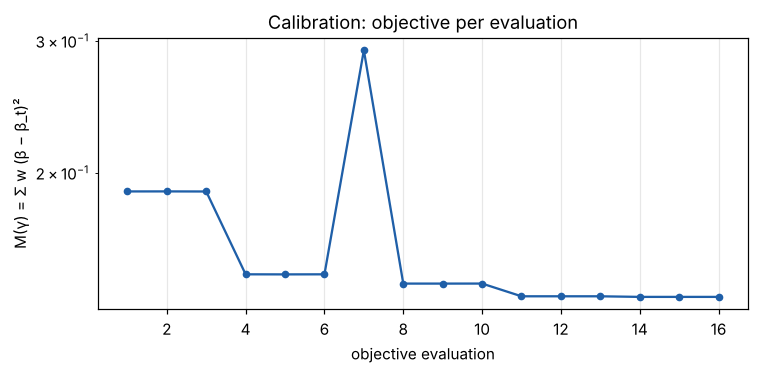

In [4]:
before, after = cal_12.sweep_before, cal_12.sweep_after
print(f"spread of β (weighted std):  before {np.sqrt(np.average((before.beta - before.beta.mean())**2, weights=before.weight)):.3f}"
      f"   after {np.sqrt(np.average((after.beta - after.beta.mean())**2, weights=after.weight)):.3f}")
save(plots.plot_beta_distribution(after, by='mode', beta_target=3.8, ref_df=before,
                                  labels=('calibrated', 'Eurocode 1.35 / 1.5'),
                                  title='Eq. 8.12: β per failure mode before and after calibration'),
     'lesson05_before_after_mode.png')
save(plots.plot_beta_vs_aQ(after, beta_target=3.8, ref_df=before,
                           title='Eq. 8.12: β against a_Q, Eurocode factors (red) and calibrated (blue)'),
     'lesson05_before_after_aQ.png')
save(plots.plot_calibration_history(cal_12), 'lesson05_history.png')

## 3. More degrees of freedom

Separate factors for wind, snow and imposed load let the optimiser
address the systematic differences between the loads (snow low, imposed
high in the status quo):

In [5]:
cal_12_loads = cc.calibrate(model, free=('gamma_G', 'gamma_Q:wind', 'gamma_Q:snow', 'gamma_Q:imposed'),
                            equation='8.12', start=cc.START_VALUES, verbose=False)
print(cal_12_loads)

calibrated gamma_G, gamma_Q:wind, gamma_Q:snow, gamma_Q:imposed  (β_t = 3.8)
  gamma_G            1.194
  gamma_Q:wind       1.937
  gamma_Q:snow       2.351
  gamma_Q:imposed    1.602
  weighted-mean β  3.741 → 3.815
  objective        7.208e-02   (42 evaluations)


## 4. The two-combination rule, eq. 8.13, with ξ free

In [6]:
cal_13 = cc.calibrate(model, free=('xi', 'gamma_G', 'gamma_Q'), equation='8.13',
                      start=cc.START_VALUES, verbose=False)
print(cal_13)

calibrated xi, gamma_G, gamma_Q  (β_t = 3.8)
  xi                 0.892
  gamma_G            1.329
  gamma_Q            1.779
  weighted-mean β  3.445 → 3.809
  objective        1.344e-01   (30 evaluations)


## 5. Comparing the calibrations

The objective value is the measure of success: the smaller, the more
uniform the reliability across the situations the code covers.

                         gamma_G  gamma_GP     xi  gamma_Q:wind  gamma_Q:snow  gamma_Q:imposed  objective  weighted-mean β
8.12: γ_G, γ_Q             1.215     1.215  0.850         1.750         1.750            1.750    0.13662            3.809
8.12: γ_G, γ_Q per load    1.194     1.194  0.850         1.937         2.351            1.602    0.07208            3.815
8.13: ξ, γ_G, γ_Q          1.329     1.329  0.892         1.779         1.779            1.779    0.13441            3.809


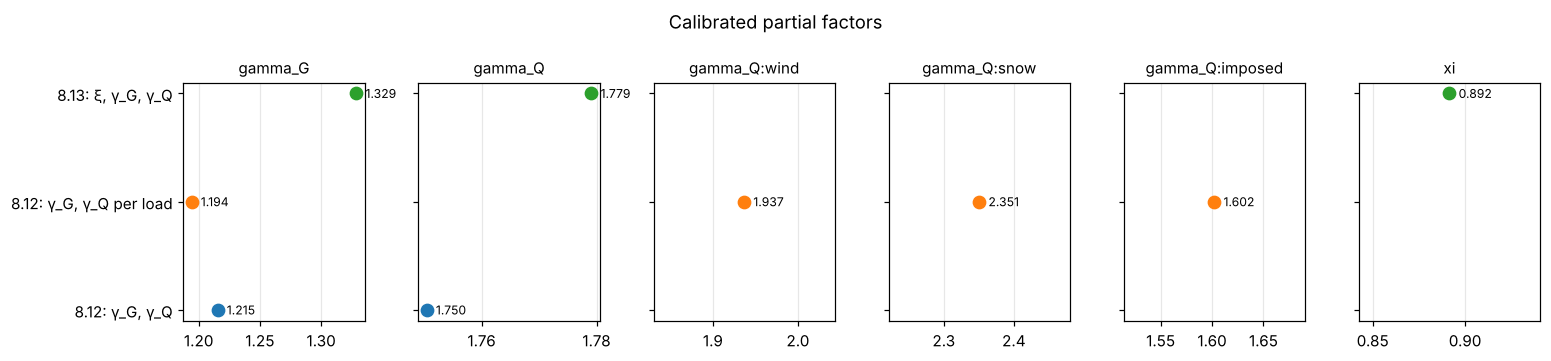

In [7]:
results = {'8.12: γ_G, γ_Q': cal_12, '8.12: γ_G, γ_Q per load': cal_12_loads, '8.13: ξ, γ_G, γ_Q': cal_13}
summary = pd.DataFrame({name: {**{k: round(v, 3) for k, v in r.factors.as_dict().items()},
                               'objective': round(r.objective, 5), 'weighted-mean β': round(r.beta_after, 3)}
                        for name, r in results.items()}).T
print(summary.to_string())
save(plots.plot_gamma_comparison(results), 'lesson05_gamma_comparison.png')
summary.to_csv('calibration_results.csv')

A few things to take from the table:

* Differentiating $\gamma_Q$ by load reduces the objective markedly:
  the snow load gets the largest factor, the imposed load the smallest.
  Whether a code should have three variable-load factors is a question
  of practicality, not of reliability.
* With ξ free, the optimiser trades ξ against $\gamma_G$ — one of the
  flat directions of the landscape. The calibrated numbers of the
  two-combination rules depend strongly on the bounds and start values.
* All calibrated values are specific to the probabilistic model, the
  target, the weights and the FORM approximation (lesson 6).

## Exercises

1. Calibrate with the target 4.3 (consequence class 3). How much do the
   factors rise? Is the increase the same for γ_G and γ_Q?
2. Calibrate eq. 8.14 with ξ free and compare with 8.13.
3. Give every design situation the same weight (`df['weight'] = const` is
   not enough — change the weights in the model) and recalibrate. Which
   failure modes gain, which lose?
4. Fix γ_G = 1.35 and calibrate γ_Q alone. Compare the objective with the
   two-parameter calibration: what does the second parameter buy?